<!-- GENERATED by scripts/build_problems.py from
     DA4CHE-admin/problems/Topic3.3-Alternate_Classification_Models/master.md
     Do not edit this file directly — your changes will be overwritten.
     Solutions and rubrics live in the private repo and must never appear here. -->

```{contents}
:local:
:depth: 2
```

# Problems: Alternate Classification Methods

:::{admonition} Get this problem set
:class: seealso

{download}`Download everything (Topic3.3-Alternate_Classification_Models_Problems.zip) <archives/Topic3.3-Alternate_Classification_Models_Problems.zip>` — the notebook and
`aqueous_solubility.csv`, in a folder that is ready to run as-is.

The Download badge at the top of the page will also give you the notebook on its own.
On Vocareum everything is already set up for you.
:::

:::{admonition} Before you start
:class: tip

This problem set accompanies {doc}`Alternate Classification Methods </3-classification/Topic3.3-Alternate_Classification_Models>`. It is worth **100 points**:

- **Part A — Skill Checks (30 pts)** — short answers, auto-graded, resubmit as often as
  you like until they pass.
- **Part B — Visualization (35 pts)** — plots plus written interpretation, peer graded.
- **Part C — Open Ended (35 pts)** — one synthesis problem, peer graded.

The parts build on each other: Part A works out the syntax you need for Part B, and
Part B produces the evidence you argue from in Part C. Do them in order.
:::



## Setup

`data/aqueous_solubility.csv` is **AqSolDB** — 9,982 compounds with a measured aqueous
solubility and seventeen computed 2D descriptors, compiled from nine public sources
(Sorkun, Khetan & Er, *Sci. Data* **6**, 143, 2019,
[doi:10.1038/s41597-019-0151-1](https://doi.org/10.1038/s41597-019-0151-1)).
`Solubility` is $\log_{10} S$ with $S$ in mol/L, so $-3$ is about 1 mM.

**Every row is a different compound** — all 9,982 `InChIKey` values are distinct. That
matters more than it sounds. Compare it with a table compiled from the literature, where one
paper contributes forty rows for the same material at forty conditions: a flexible classifier
can then work out which *paper* a row came from, and what gets reported as accuracy is
partly that. Here a random train/test split really does hold out unseen chemistry.

A compound counts as **soluble** when $\log_{10} S \ge -3$. That cut is a convention rather
than a physical boundary, chosen because it splits the set nearly in half and so keeps
accuracy from being dominated by one class.

The two descriptors used in Parts A and B are **`MolLogP`** (the octanol/water partition
coefficient, a direct measure of how much a molecule prefers oil to water) and
**`MolWt`**. Together they are the classic solubility screening plane, and they are only
mildly correlated, which will matter for one of the three classifiers.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
try:
    plt.style.use('../settings/plot_style.mplstyle')   # available inside the book
except OSError:
    pass                                              # downloaded notebook: use defaults

df = pd.read_csv('data/aqueous_solubility.csv')
df['soluble'] = (df['Solubility'] >= -3.0).astype(int)

FEATURES = ['MolLogP', 'MolWt']
X = df[FEATURES].values
y = df['soluble'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print(f"{len(df)} compounds, {df['InChIKey'].nunique()} unique InChIKeys")
print(f"soluble {int(y.sum())}   insoluble {int((1 - y).sum())}   "
      f"fraction soluble {y.mean():.6f}")
print(f"{len(y_train)} training rows, {len(y_test)} test rows "
      f"({int(y_test.sum())} of the test compounds are soluble)")

9982 compounds, 9982 unique InChIKeys
soluble 5687   insoluble 4295   fraction soluble 0.569726
6987 training rows, 2995 test rows (1706 of the test compounds are soluble)


`MolWt` runs to the hundreds while `MolLogP` is single digits, so the two descriptors are
on scales that differ by a factor of about 50. A decision tree does not care — it splits
one feature at a time — and Gaussian Naive Bayes does not care either, because it fits a
separate variance per feature. **k-nearest neighbors does care**, because it adds squared
differences across features, and the larger-scaled feature would dominate every distance.
So a standardized copy of the split is prepared here alongside the raw one.

In [2]:
scaler = StandardScaler().fit(X_train)     # fitted on the TRAINING rows only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"feature means  {np.round(scaler.mean_, 4)}")
print(f"feature scales {np.round(scaler.scale_, 4)}")

feature means  [  2.0047 265.6102]
feature scales [  3.507  184.9003]


One helper draws a fitted model's decision regions, so you do not have to redo the contour
bookkeeping in every panel of Part B.

It draws over a fixed window rather than the full data range, and that choice matters. A few
extreme compounds stretch the range a long way — `MolWt` reaches 5,299 g/mol and `MolLogP`
runs from −40.9 to 68.5 — so a plot drawn to the data's own limits puts 99% of the compounds,
and all of the interesting boundary, inside about 5% of the frame. The default window below
holds 95.8% of the compounds and fills the axes with them.

In [3]:
PLOT_XLIM = (-6, 12)      # MolLogP
PLOT_YLIM = (0, 700)      # MolWt, g/mol


def plot_regions(ax, model, standardized, xlim=PLOT_XLIM, ylim=PLOT_YLIM, n_grid=300):
    """Shade `model`'s predicted regions over the (MolLogP, MolWt) plane.

    ax           the axes to draw on
    model        any fitted sklearn classifier
    standardized True for a model fitted on X_train_s, False for one fitted on X_train.
                 Get this wrong and the regions are drawn in the wrong coordinates.
    xlim, ylim   the window to draw; widen them to see the tails.

    Returns the axes, so calls can be chained.
    """
    pg, wg = np.meshgrid(np.linspace(*xlim, n_grid), np.linspace(*ylim, n_grid))
    grid = np.column_stack([pg.ravel(), wg.ravel()])
    if standardized:
        grid = scaler.transform(grid)
    Z = model.predict(grid).reshape(pg.shape)
    ax.contourf(pg, wg, Z, levels=[-0.5, 0.5, 1.5], alpha=0.25)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel('MolLogP')
    ax.set_ylabel('MolWt [g/mol]')
    return ax

The pattern is the same every time, and you will use a version of it in Part B. Fit a
classifier, hand it to `plot_regions` with the `standardized` flag matching how you fitted it,
then scatter compounds on top to see where the boundary falls relative to the data. The shaded
region is where the model predicts *soluble*.

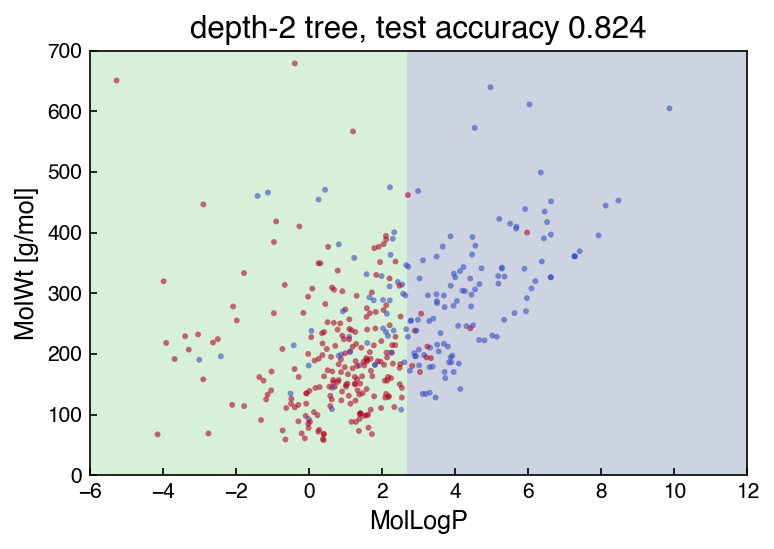

In [4]:
demo = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(5.5, 4))
plot_regions(ax, demo, standardized=False)         # fitted on X_train, so False
ax.scatter(X_test[:400, 0], X_test[:400, 1], c=y_test[:400],
           cmap='coolwarm', s=8, alpha=0.6, edgecolors='none')
ax.set_title(f'depth-2 tree, test accuracy {demo.score(X_test, y_test):.3f}')
plt.tight_layout();

Two axis-aligned cuts, which is all a depth-2 tree can draw. Part B asks you to put this
alongside the other two algorithms and account for the differences.

Run this once. It defines the `check` helper used after each Part A answer. It will
not run inside the book — use the downloaded notebook.

In [ ]:
# Run this once. It defines `check`, used after each Part A answer below.
import hashlib

_EXPECTED = {
    'q1': (5, ['b760e0e82a80', '3e1282933259', 'a95356ce7086', 'b38ffcfa4a95', 'd2e015e721ec', '74394099eec5', 'e80c769a9822', '6a3ceb42c82c', '84ac8cecd158', '2e18b437d351', '1bf56a15cbc3', 'e760aff63b93', '2a088bc5843b']),
    'q2': (4, ['c49d399bc042', 'b8e588b488ce', '38223dbcfebe', '75bab596aa78', '2298ba726416', '500c23960fcb', 'ecd6796740a0', 'c2dfddaf3839', 'b7800236740f', 'af16ddbeb994', '46d33dfd1571', '0205ebd291d6', '9b205fddc7c6', '4b2811126169', 'c26f96765cfb', 'dbfad1eceb5e', 'a76c190b67db']),
    'q3': (4, ['617d697f0bec', 'f02cb9fea9d6', 'b65875f178fd', '5b8d040fe3a3', '709e711cc940', 'de3065a39fc3', '36cea21d4d44', 'a26f03a60696', '13ff9d3b02bf', '9a1b3cb8fc6c', '156c3cf8899e', '200788c3d984', '4d5dfa679b45', 'f3b15ad8e718', '12e927bab7c9', '98802503a8f2', 'e74418aac84d', 'e46ddb80bf47', '4599aeb8fbaa']),
}

def check(qid, value):
    """Compare an answer against a stored digest. Practice only -- nothing is recorded."""
    places, digests = _EXPECTED[qid]
    if value is Ellipsis:
        print(f"{qid}: not answered yet")
        return
    got = hashlib.sha256(f"{float(value):.{places}f}".encode()).hexdigest()[:12]
    print(f"{qid}: {'correct' if got in digests else 'not the expected value'}")

---

## Part A — Skill Checks (30 pts)

Three questions, 10 points each, and together they are one controlled experiment. A1 is the
number every model has to beat. A2 and A3 then fit **the same two descriptors** on **the
same split** and differ only in the algorithm — one generative and parametric, one local and
non-parametric. Compare all three when you have them.

Fit on the training rows, score on the test rows. Report **accuracy** throughout, using each
estimator's own `.score()` method.

### A1. The number to beat (10 pts)

:::{exercise}
:label: pr-cls-sol-baseline

A classifier that ignores the descriptors entirely and always answers with the larger class
still scores something, and every model below has to beat it.

Using `y_test` only, compute the fraction of test compounds belonging to the **more common**
of the two classes.

Assign it to `baseline_accuracy`.
:::

In [ ]:
# YOUR CODE HERE
baseline_accuracy = ...

In [ ]:
check("q1", baseline_accuracy)

### A2. Gaussian Naive Bayes (10 pts)

:::{exercise}
:label: pr-cls-nb-solubility

Fit `GaussianNB` on the **unstandardized** training features and score it on the
unstandardized test features.

Assign the test accuracy to `acc_nb`.

Naive Bayes needs no standardization — it estimates a mean and a variance for each feature
within each class, so rescaling a column rescales its fitted variance by the same factor and
the predictions do not move.
:::

In [ ]:
# YOUR CODE HERE
acc_nb = ...

In [ ]:
check("q2", acc_nb)

### A3. k-nearest neighbors (10 pts)

:::{exercise}
:label: pr-cls-knn-standardized

Fit `KNeighborsClassifier` with `n_neighbors=25` on the **standardized** training features
(`X_train_s`) and score it on `X_test_s`.

Assign the test accuracy to `acc_knn`.

Use the standardized copy. Fitting the same model on the raw features gives a different — and
worse — answer, and Part B asks you to explain why.
:::

In [ ]:
# YOUR CODE HERE
acc_knn = ...

In [ ]:
check("q3", acc_knn)

---

## Part B — Visualization (35 pts)

Part A left two things unexplained. First, *why* Naive Bayes trails by ten points on exactly
the same two descriptors. It was given the same information, so the answer has to be about the
**shape** of the boundary it can draw. Second, the hyperparameter: $k = 25$ was handed to you,
and nothing so far says it is a good choice.

Both are questions you can answer by drawing. You will plot the three decision regions to see
what each algorithm's boundary can and cannot bend around, then sweep the one hyperparameter
that controls flexibility in each of the two non-parametric models. Use the chapter's
vocabulary throughout: a model too rigid to follow the data **underfits** (high bias), and one
flexible enough to follow the noise **overfits** (high variance).

:::{exercise}
:label: pr-cls-bias-variance-sweeps

**1. Draw the three decision regions.** Make a 1×3 figure, one panel per classifier:
`GaussianNB`, `KNeighborsClassifier(n_neighbors=25)`, and
`DecisionTreeClassifier(max_depth=5, random_state=0)`. Use `plot_regions` exactly as the
Setup demonstrates it, keeping its default window so the three panels are comparable, and
remember the `standardized` flag has to match how each model was fitted. Scatter a sample of
the test compounds on top, colored by their true class.

**2. Sweep $k$.** Fit `KNeighborsClassifier` on the standardized training features for
$k \in \{1, 3, 5, 10, 25, 50, 100, 250\}$. Plot **training and test accuracy on the same
axes** against $k$, with $k$ on a log scale. Mark the best test accuracy.

**3. Sweep tree depth.** Fit `DecisionTreeClassifier(random_state=0)` on the unstandardized
training features for `max_depth` in `[1, 2, 3, 5, 8, 12, None]`. Plot training and test
accuracy against depth on the same axes, and report the number of leaves at the largest
depth.

**4. Report the scaling penalty.** Refit the $k = 25$ model on the raw features and state
both accuracies.

**5. Account for the gap, in 2–3 sentences.** Part A left Naive Bayes ten points behind the
other two on identical descriptors. Explain why, naming the boundary shape at least one
algorithm draws in task 1 and citing one training-minus-test gap you measured in task 2 or 3.

Label your axes with units. Use a log-scaled $x$-axis for the $k$ sweep.
:::

In [ ]:
# YOUR CODE HERE
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

---

## Part C — Open Ended (35 pts)

Part B tuned each algorithm on two descriptors. The file carries seventeen, and four of the
others are the ones a chemist would reach for next: polar surface area and counts of hydrogen
bond donors, acceptors and rotatable bonds. Whether they help is two questions, not one —
whether the extra information helps a model of *fixed* complexity, and whether the right
complexity is different once the feature space is bigger. Task 1 asks the first with the
hyperparameters nailed down; task 2 re-opens them.

Then you have to choose. Suppose this classifier pre-screens a compound library for an
experimental solubility campaign, deciding which compounds go to the bench. A compound wrongly
called insoluble is never measured and its solubility is never found — a missed hit. A
compound wrongly called soluble costs one wasted measurement. Those costs are not equal, and
accuracy weighs them as if they were, which is why every table below asks for precision and
recall alongside it.

:::{exercise}
:label: pr-cls-screen-model-choice

**1. Add four descriptors, holding every hyperparameter fixed.** Build a six-descriptor
feature set:

```
['MolLogP', 'MolWt', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumRotatableBonds']
```

Re-split and re-standardize it exactly as the Setup does for the two-descriptor set
(`test_size=0.3, random_state=0, stratify=y`, scaler fitted on the training rows). Then fit
all three models **at the settings Part B chose** — k-NN at your best $k$, the tree at your
best `max_depth`, Naive Bayes as it comes — and report each model's test accuracy, precision
and recall on **both** feature sets in one table. State how much each model gained or lost.

**2. Re-tune on the six-descriptor set.** The best setting for a model is a property of the
feature space, not a constant. Using the **training rows only** — `cross_val_score` over a
grid, never the test set — re-pick $k$ for k-NN and `max_depth` for the tree. Naive Bayes has
no flexibility hyperparameter; say so. Report the new best settings with their
cross-validated scores, then score each re-tuned model once on the test rows. Say which
model's best setting moved, and how far.

**3. Propose the best model for the screen.** Using your tables from tasks 1 and 2, plus any
further analysis you care to run, recommend one model to deploy. Give the evidence, then
state the recommendation and the metric you chose it on in **2–3 sentences**.

There is more than one defensible recommendation. You are graded on whether the evidence you
produced supports the one you make.
:::

In [ ]:
# YOUR CODE HERE

---

## Summary

- **Part A** fixed three reference numbers on one split and one pair of descriptors: what a
  classifier that ignores the descriptors scores, what Gaussian Naive Bayes scores, and what
  k-NN at $k=25$ scores. The two fitted models beat the first, and the local one beats the
  parametric one by about ten points.
- **Part B** explained the gap by drawing it. Each algorithm produces one kind of boundary —
  a conic, a local contour, an axis-aligned staircase — and the two sweeps located the
  underfitting and overfitting ends of $k$ and `max_depth`.
- **Part C** made two controlled changes in order — four more descriptors at fixed
  hyperparameters, then re-tuning on that larger feature set — and then asked which model to
  deploy once a false negative costs more than a false positive, which is where the accuracy
  ranking and the recall ranking disagree.

## Additional Reading

1. M. C. Sorkun, A. Khetan and S. Er, "AqSolDB, a curated reference set of aqueous
   solubility and 2D descriptors for a diverse set of compounds", *Scientific Data* **6**,
   143 (2019). [doi:10.1038/s41597-019-0151-1](https://doi.org/10.1038/s41597-019-0151-1).
   Deposit: [doi:10.7910/DVN/OVHAW8](https://doi.org/10.7910/DVN/OVHAW8) (CC0).
2. Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, Ch. 13 (k-NN),
   Ch. 6.6 (Naive Bayes), Ch. 9 (trees) — [free PDF](https://hastie.su.domains/ElemStatLearn/).
3. scikit-learn User Guide:
   [Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html),
   [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html),
   [Decision Trees](https://scikit-learn.org/stable/modules/tree.html).